<a href="https://colab.research.google.com/github/aurora-nat/machine-vision-course/blob/main/labs/lab5/object_detection_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Object Detection with PyTorch

This notebook is about **object detection** using **PyTorch** on a **pedestrian dataset**.

We will use:
- **Penn-Fudan Pedestrian** dataset
- **Faster R-CNN** from `torchvision`
- A custom dataset class that returns bounding boxes and labels
- A simple training and evaluation pipeline.

## Learning goals

By the end of this notebook,you should be able to:
1. Explain what object detection is
2. Understand the format of bounding-box annotations
3. Build a custom PyTorch `Dataset` for object detection
4. Fine-tune a pretrained Faster R-CNN model
5. Visualize predictions on test images

Penn-Fudan contains real street scenes with pedestrians and corresponding segmentation masks.  
We will convert each pedestrian mask into a **bounding box**, so the notebook focuses on **object detection** rather than segmentation.

## What is object detection?

Object detection answers two questions:
1. **What object is present?**
2. **Where is it in the image?**

Unlike image classification, object detection predicts one or more **bounding boxes** plus a **class label** for each object.

In this notebook there is only one foreground class:

- `1 = pedestrian`

Class `0` is reserved for background.

In [1]:
# Colab / environment setup
import sys
import subprocess
import matplotlib
import PIL

In [2]:
import os
import random
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

print("Torch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Torch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Using device: cpu


## Download the Penn-Fudan dataset

The dataset contains:
- RGB images in `PNGImages/`
- Pedestrian instance masks in `PedMasks/`

Each pedestrian instance in a mask has a different pixel value.  
We will convert each instance mask into:
- a binary mask for that instance
- a bounding box `(xmin, ymin, xmax, ymax)`
- a class label `1`

In [3]:
# Download dataset
data_root = Path("data")
data_root.mkdir(exist_ok=True)

zip_path = data_root / "PennFudanPed.zip"
extract_dir = data_root / "PennFudanPed"

if not extract_dir.exists():
    if not zip_path.exists():
        url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
        print("Downloading dataset...")
        urllib.request.urlretrieve(url, zip_path)
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_root)

print("Dataset ready at:", extract_dir.resolve())
print("Number of images:", len(list((extract_dir / "PNGImages").glob("*.png"))))

Extracting dataset...
Dataset ready at: /content/data/PennFudanPed
Number of images: 170


## Visualize a raw image and mask

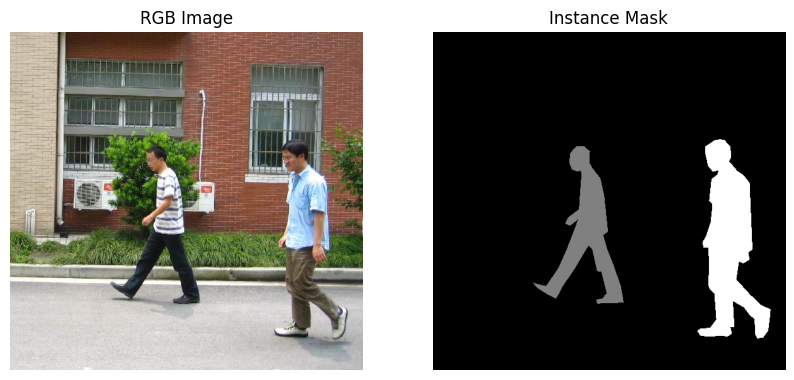

In [4]:

images_dir = extract_dir / "PNGImages"
masks_dir = extract_dir / "PedMasks"

sample_img_path = sorted(images_dir.glob("*.png"))[0]
sample_mask_path = masks_dir / sample_img_path.name.replace(".png", "_mask.png")

img = Image.open(sample_img_path).convert("RGB")
mask = Image.open(sample_mask_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img)
axes[0].set_title("RGB Image")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Instance Mask")
axes[1].axis("off")
plt.show()

## Build a custom PyTorch dataset

For `torchvision` detection models, each training example should return:

- `image`: a tensor of shape `[3, H, W]`
- `target`: a dictionary with keys such as:
  - `boxes`: shape `[N, 4]`
  - `labels`: shape `[N]`
  - `image_id`
  - `area`
  - `iscrowd`

Here, `N` is the number of objects in the image.

In [5]:

class PennFudanDetectionDataset(Dataset):
    def __init__(self, root, transforms=None):
        self.root = Path(root)
        self.transforms = transforms
        self.imgs = sorted((self.root / "PNGImages").glob("*.png"))
        self.masks = sorted((self.root / "PedMasks").glob("*.png"))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img_path = self.imgs[idx]
        mask_path = self.masks[idx]

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        mask = np.array(mask)

        # Each unique value corresponds to a different pedestrian instance.
        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0]  # remove background

        # Binary mask for each object: [N, H, W]
        masks = mask == obj_ids[:, None, None]

        boxes = []
        for i in range(len(obj_ids)):
            pos = np.where(masks[i])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])

            # Safety check: skip degenerate boxes
            if xmax > xmin and ymax > ymin:
                boxes.append([xmin, ymin, xmax, ymax])

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            area = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.ones((boxes.shape[0],), dtype=torch.int64)  # class 1 = pedestrian
            area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
            iscrowd = torch.zeros((boxes.shape[0],), dtype=torch.int64)

        image_id = torch.tensor([idx])

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd,
        }

        img = F.to_tensor(img)

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

## Check one dataset example

In [6]:
dataset = PennFudanDetectionDataset(extract_dir)
image, target = dataset[0]

print("Image tensor shape:", image.shape)
print("Target keys:", target.keys())
print("Boxes shape:", target["boxes"].shape)
print("Labels:", target["labels"])

Image tensor shape: torch.Size([3, 536, 559])
Target keys: dict_keys(['boxes', 'labels', 'image_id', 'area', 'iscrowd'])
Boxes shape: torch.Size([2, 4])
Labels: tensor([1, 1])


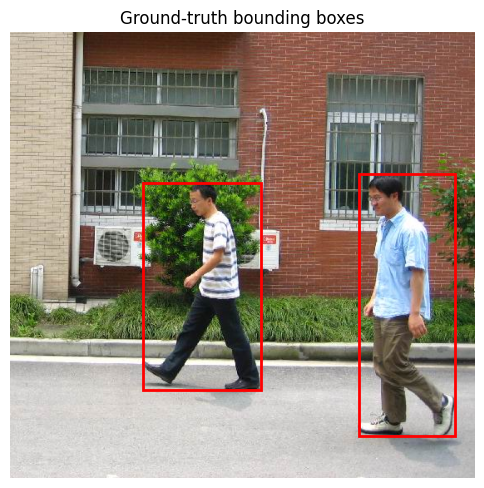

In [7]:
def show_image_with_boxes(image_tensor, boxes, title="Image with Boxes"):
    image_np = image_tensor.permute(1, 2, 0).cpu().numpy()

    fig, ax = plt.subplots(1, figsize=(6, 8))
    ax.imshow(image_np)
    for box in boxes:
        xmin, ymin, xmax, ymax = box.tolist()
        rect = patches.Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            linewidth=2, edgecolor="red", facecolor="none"
        )
        ax.add_patch(rect)
    ax.set_title(title)
    ax.axis("off")
    plt.show()

show_image_with_boxes(image, target["boxes"], title="Ground-truth bounding boxes")

## Train / validation split

We keep the notebook classroom-friendly by using:
- a training set
- a validation set
- a smaller number of epochs

This helps the notebook finish in a reasonable time on Colab.

In [8]:
full_dataset = PennFudanDetectionDataset(extract_dir)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size], generator=generator)

print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))

Train size: 136
Validation size: 34


In [15]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

## Build the model

We use a pretrained **Faster R-CNN ResNet-50 FPN** model and replace the classification head.

Since we have:
- `1` foreground class: pedestrian
- plus background internally

we set `num_classes = 2`.

In [10]:
def get_model(num_classes):
    model = fasterrcnn_resnet50_fpn(weights="DEFAULT")
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

num_classes = 2  # background + pedestrian
model = get_model(num_classes)
model.to(device)
print("Model ready.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 215MB/s]


Model ready.


## Training utilities

In [11]:
def train_one_epoch(model, optimizer, data_loader, device):
    model.train()
    running_loss = 0.0

    for images, targets in data_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        running_loss += losses.item()

    return running_loss / max(len(data_loader), 1)


@torch.no_grad()
def evaluate_loss(model, data_loader, device):
    # Detection models return losses in train mode when targets are provided.
    model.train()
    running_loss = 0.0

    for images, targets in data_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        running_loss += losses.item()

    return running_loss / max(len(data_loader), 1)

In [12]:
def compute_iou(box_a, box_b):
    xa1, ya1, xa2, ya2 = box_a
    xb1, yb1, xb2, yb2 = box_b

    inter_x1 = max(xa1, xb1)
    inter_y1 = max(ya1, yb1)
    inter_x2 = min(xa2, xb2)
    inter_y2 = min(ya2, yb2)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    area_a = max(0.0, xa2 - xa1) * max(0.0, ya2 - ya1)
    area_b = max(0.0, xb2 - xb1) * max(0.0, yb2 - yb1)

    union_area = area_a + area_b - inter_area + 1e-6
    return inter_area / union_area


@torch.no_grad()
def simple_validation_iou(model, data_loader, device, score_threshold=0.5):
    model.eval()
    ious = []

    for images, targets in data_loader:
        images = [img.to(device) for img in images]
        outputs = model(images)

        for output, target in zip(outputs, targets):
            pred_boxes = output["boxes"].detach().cpu()
            pred_scores = output["scores"].detach().cpu()
            gt_boxes = target["boxes"].detach().cpu()

            keep = pred_scores >= score_threshold
            pred_boxes = pred_boxes[keep]

            if len(pred_boxes) == 0 or len(gt_boxes) == 0:
                continue

            matched_ious = []
            for gt_box in gt_boxes:
                best_iou = 0.0
                for pred_box in pred_boxes:
                    iou = compute_iou(gt_box.tolist(), pred_box.tolist())
                    best_iou = max(best_iou, iou)
                matched_ious.append(best_iou)

            if matched_ious:
                ious.extend(matched_ious)

    if len(ious) == 0:
        return 0.0
    return float(np.mean(ious))

## Train the model

To keep this practical, we train for only a few epochs.  
You can increase the number later for better performance.

In [16]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

num_epochs = 3

train_losses = []
val_losses = []
val_ious = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, optimizer, train_loader, device)
    val_loss = evaluate_loss(model, val_loader, device)
    val_iou = simple_validation_iou(model, val_loader, device, score_threshold=0.5)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_ious.append(val_iou)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val IoU: {val_iou:.4f}")

Epoch 1/3 | Train Loss: 0.2607 | Val Loss: 0.1159 | Val IoU: 0.8779
Epoch 2/3 | Train Loss: 0.1176 | Val Loss: 0.1038 | Val IoU: 0.8892
Epoch 3/3 | Train Loss: 0.0906 | Val Loss: 0.1087 | Val IoU: 0.8733


## Plot training curves

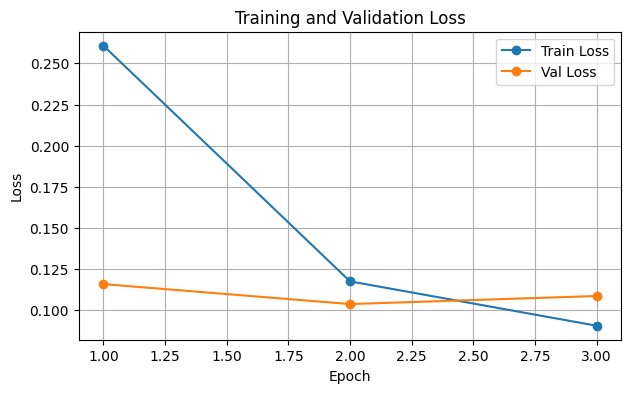

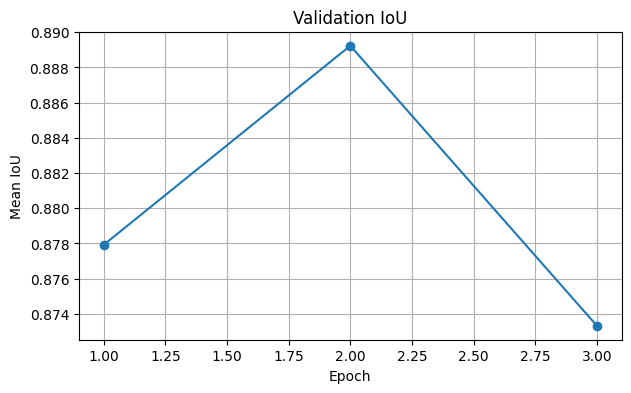

In [17]:
epochs = np.arange(1, num_epochs + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.plot(epochs, val_losses, marker="o", label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, val_ious, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean IoU")
plt.title("Validation IoU")
plt.grid(True)
plt.show()

## Run inference on validation images

In [18]:
@torch.no_grad()
def predict(model, image_tensor, device, score_threshold=0.5):
    model.eval()
    output = model([image_tensor.to(device)])[0]

    boxes = output["boxes"].detach().cpu()
    scores = output["scores"].detach().cpu()
    labels = output["labels"].detach().cpu()

    keep = scores >= score_threshold
    return boxes[keep], scores[keep], labels[keep]

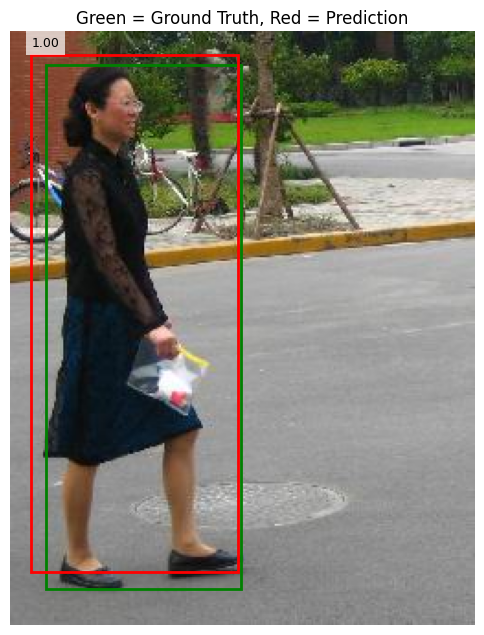

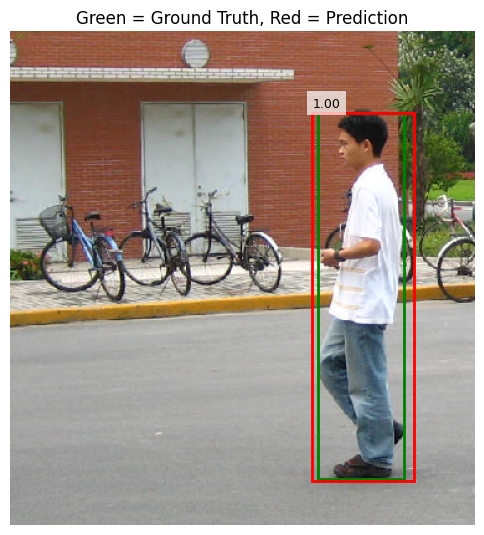

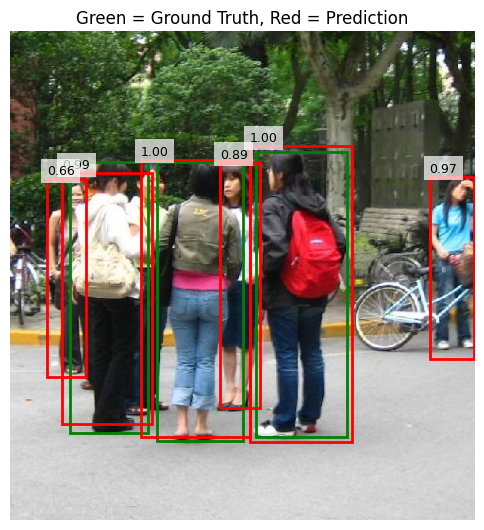

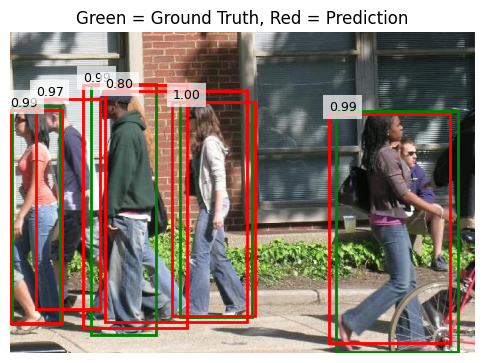

In [19]:
def visualize_predictions(model, dataset, device, num_images=4, score_threshold=0.5):
    model.eval()
    indices = random.sample(range(len(dataset)), k=min(num_images, len(dataset)))

    for idx in indices:
        image, target = dataset[idx]
        pred_boxes, pred_scores, pred_labels = predict(model, image, device, score_threshold)

        image_np = image.permute(1, 2, 0).cpu().numpy()
        fig, ax = plt.subplots(1, figsize=(6, 8))
        ax.imshow(image_np)

        # Ground truth in green
        for box in target["boxes"]:
            xmin, ymin, xmax, ymax = box.tolist()
            rect = patches.Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                linewidth=2, edgecolor="green", facecolor="none"
            )
            ax.add_patch(rect)

        # Predictions in red
        for box, score in zip(pred_boxes, pred_scores):
            xmin, ymin, xmax, ymax = box.tolist()
            rect = patches.Rectangle(
                (xmin, ymin), xmax - xmin, ymax - ymin,
                linewidth=2, edgecolor="red", facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(xmin, max(0, ymin - 5), f"{score:.2f}", fontsize=9,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))

        ax.set_title("Green = Ground Truth, Red = Prediction")
        ax.axis("off")
        plt.show()

visualize_predictions(model, val_dataset, device, num_images=4, score_threshold=0.5)

## Questions

1. What happens if we increase the score threshold during inference?
2. Why might validation IoU improve even when the training loss is noisy?

## Extension ideas

- Train for more epochs
- Add data augmentation such as horizontal flips
- Try another detection model from `torchvision`
- Evaluate precision and recall
- Use a multi-class dataset such as Pascal VOC

## Summary

In this notebook, you learned how to:
- prepare a real-world detection dataset
- convert instance masks into bounding boxes
- train a Faster R-CNN detector in PyTorch
- visualize predictions
- measure bounding-box quality with IoU
